first 5 targets : ['/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP059691410-L1.1_cache', '/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP059691420-L1.1_cache', '/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP062171410-L1.1_cache', '/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP068151420-L1.1_cache', '/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP070631410-L1.1_cache']


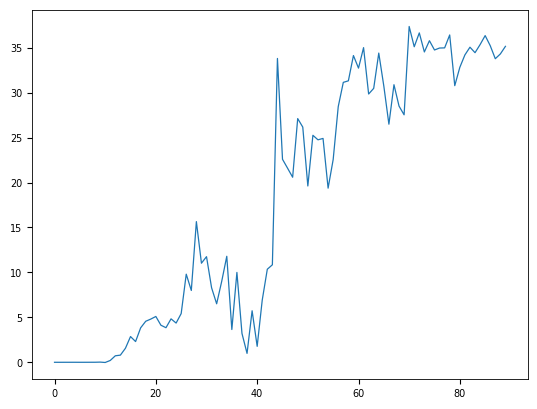

In [3]:
import importlib, os
import torch
import matplotlib.pyplot as plt
import util_collector; importlib.reload(util_collector)
import script_CoreExplorer; importlib.reload(script_CoreExplorer)
import claude_script_PaperResults as pr; importlib.reload(pr)
targets = ['/mnt/d/ALOS1-Landfast/BeaufortSouth/' + el for el in os.listdir('/mnt/d/ALOS1-Landfast/BeaufortSouth/') if el[-5:] == 'cache']
print('first 5 targets :', targets[:5])

if True:
    model, vl, floqs = pr.load_model('260815_DiffusionBlock_langevin0.05_epoch500_t128h8d16_RESICE.pth')
    item = model(torch.zeros(1,1,462).cuda())
    plt.plot(model.unwhitener(item.detach())[0,0,:90].cpu())

ALPSRP059691410-L1.1_cache: cached, skipping
ALPSRP059691420-L1.1_cache: cached, skipping
ALPSRP062171410-L1.1_cache: cached, skipping
ALPSRP068151420-L1.1_cache: cached, skipping
ALPSRP070631410-L1.1_cache: cached, skipping
ALPSRP070631420-L1.1_cache: cached, skipping
ALPSRP072381420-L1.1_cache: cached, skipping
ALPSRP094991420-L1.1_cache: cached, skipping
ALPSRP099221420-L1.1_cache: cached, skipping
ALPSRP121831420-L1.1_cache: cached, skipping
ALPSRP126061420-L1.1_cache: cached, skipping
ALPSRP167051410-L1.1_cache: cached, skipping
ALPSRP167051420-L1.1_cache: cached, skipping
ALPSRP169531410-L1.1_cache: cached, skipping
ALPSRP169531420-L1.1_cache: cached, skipping
ALPSRP171281410-L1.1_cache: cached, skipping
ALPSRP171281420-L1.1_cache: cached, skipping
ALPSRP173031420-L1.1_cache: cached, skipping
ALPSRP173761410-L1.1_cache: cached, skipping
ALPSRP173761420-L1.1_cache: cached, skipping
ALPSRP176241410-L1.1_cache: cached, skipping
ALPSRP177991410-L1.1_cache: cached, skipping
ALPSRP1779

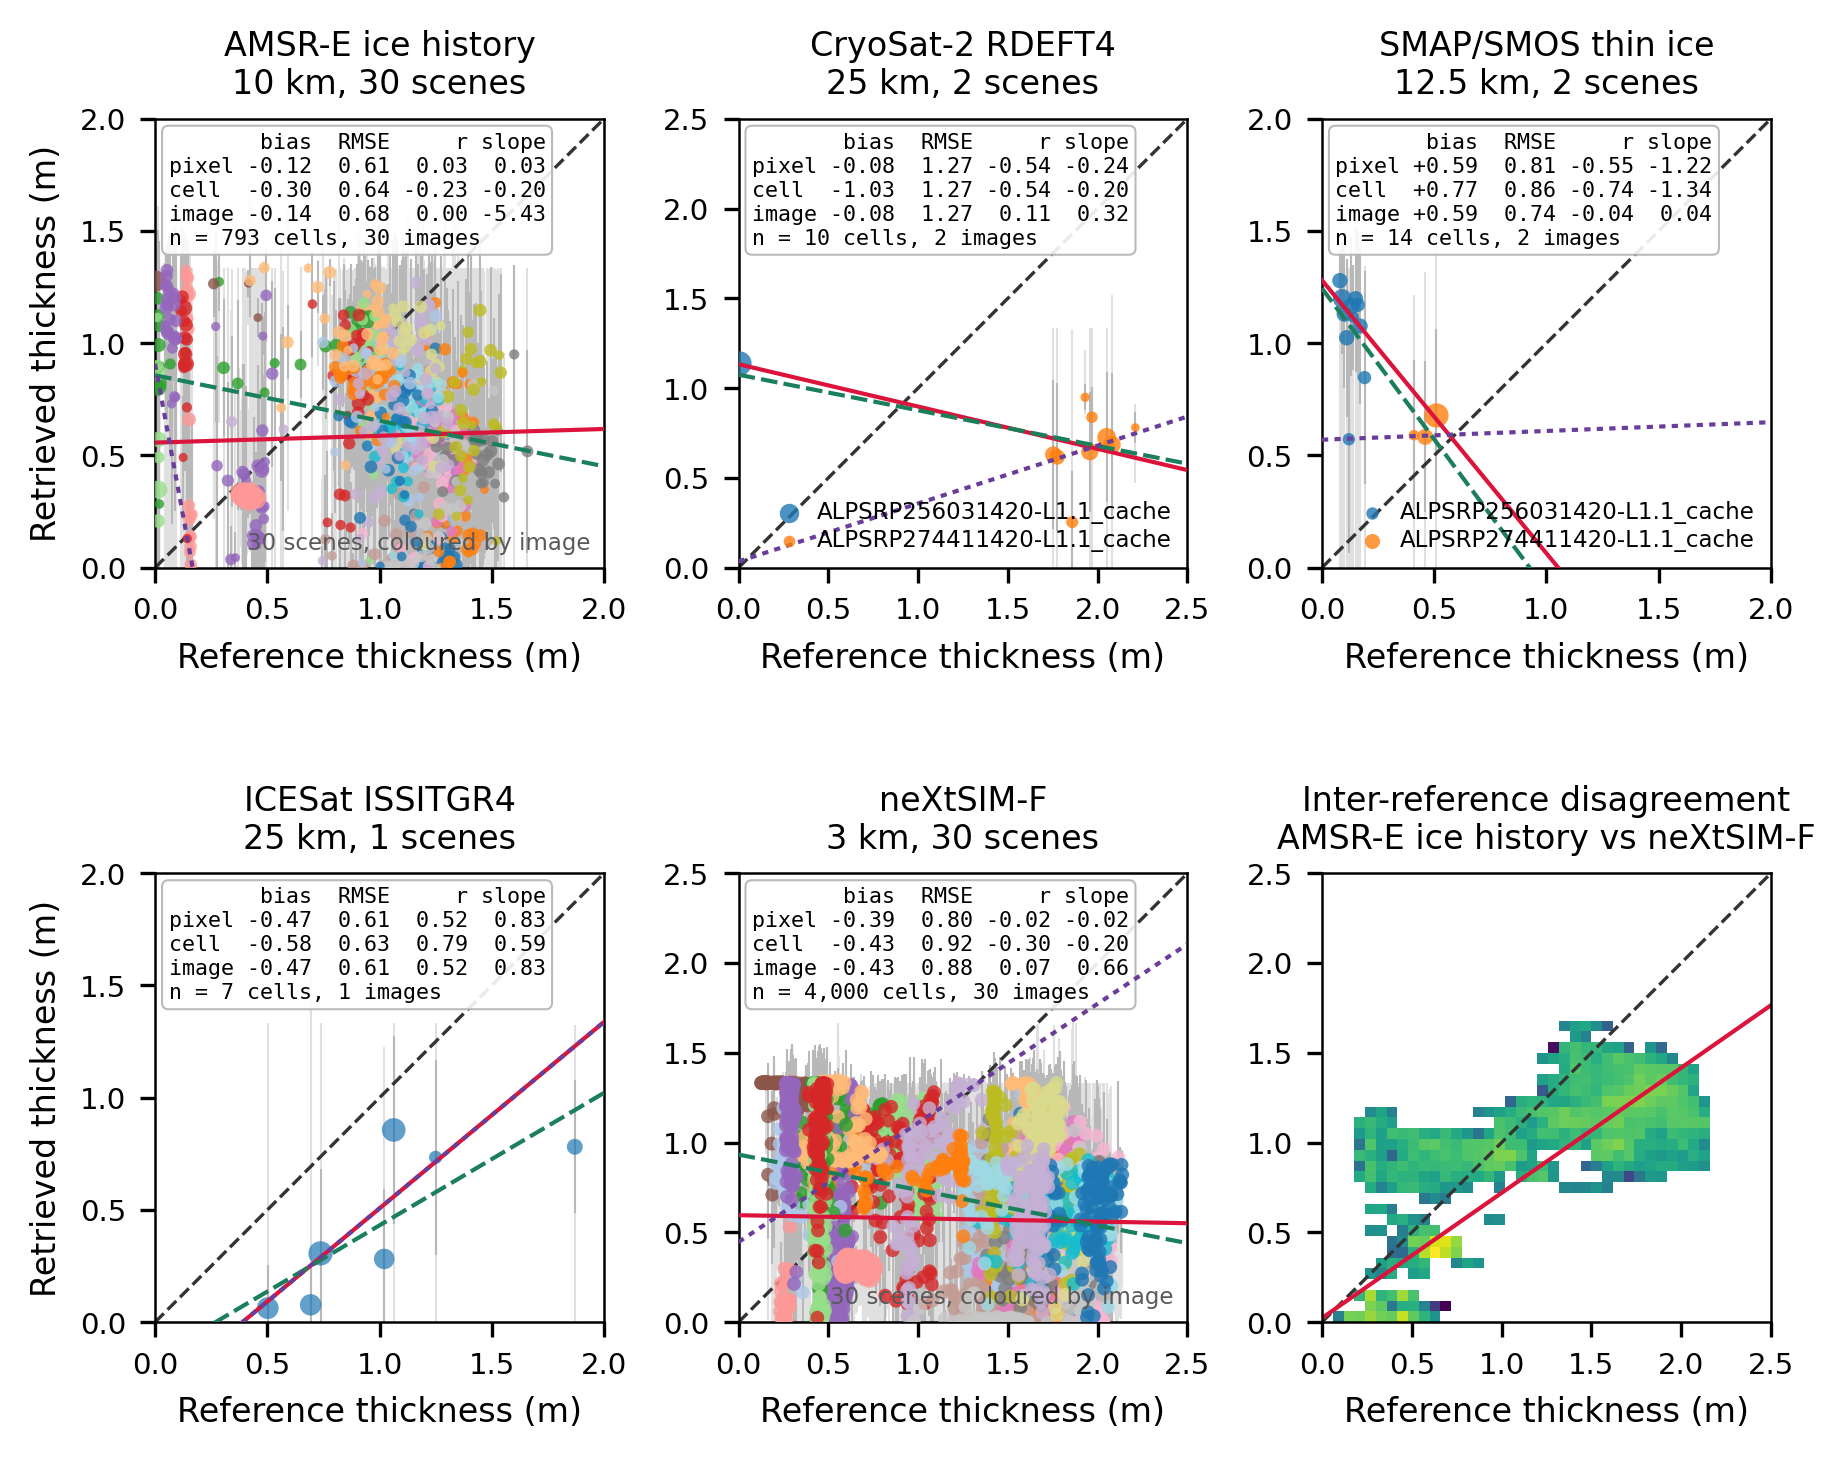

In [4]:
#model, vl, floqs = pr.load_model('260815_DiffusionBlock_langevin0.05_epoch500_t128h8d16_RESICE.pth
#model = torch.load('260815_DiffusionBlock_langevin0.05_epoch500_t128h8d16_RESICE.pth', weights_only=False)

#for targ in targets:
#    pr.resummarize(targ)
results = pr.run_scenes(targets, model, vl, floqs, skip_existing=True, reuse_references=True, sr=4)      # skips what's cached
#results = pr.run_scenes([targets[0]], model, vl, floqs, skip_existing=True)      # skips what's cached

rows = pr.comparison_table(results)                     # prints as it goes
fig  = pr.plot_comparison(results, figsize=(6, 5)); fig.savefig('figure10.png')

#rows4, arrays = pr.evaluate_heldout(model, vl, floqs)   # Table 4
#pr.plot_depth_rmse(rows4, vl)

  growth    20 scenes | AMSR_KH 20  CS2 2  SMOS 2  IC1 1  neXtSIM 20
  melt      10 scenes | AMSR_KH 10  CS2 0  SMOS 0  IC1 0  neXtSIM 10
growth (20 scenes):
  AMSR-E ice history       pixel: bias -0.180 RMSE 0.625 slope 0.01 | cell: bias -0.411 RMSE 0.749 slope -0.18 | 49,950,720 px / 528 cells / 20 scenes
  CryoSat-2 RDEFT4         pixel: bias -0.077 RMSE 1.270 slope -0.24 | cell: bias -1.032 RMSE 1.272 slope -0.20 | 2,875,392 px / 10 cells / 2 scenes
  SMAP/SMOS thin ice       pixel: bias +0.591 RMSE 0.814 slope -1.22 | cell: bias +0.772 RMSE 0.855 slope -1.34 | 2,875,392 px / 14 cells / 2 scenes
  ICESat ISSITGR4          pixel: bias -0.468 RMSE 0.608 slope 0.83 | cell: bias -0.577 RMSE 0.632 slope 0.59 | 1,437,696 px / 7 cells / 1 scenes
  neXtSIM-F                pixel: bias -0.501 RMSE 0.826 slope 0.04 | cell: bias -0.627 RMSE 1.017 slope -0.14 | 49,950,720 px / 11,077 cells / 20 scenes
melt (10 scenes):
  AMSR-E ice history       pixel: bias +0.092 RMSE 0.566 slope -0.32 | cell

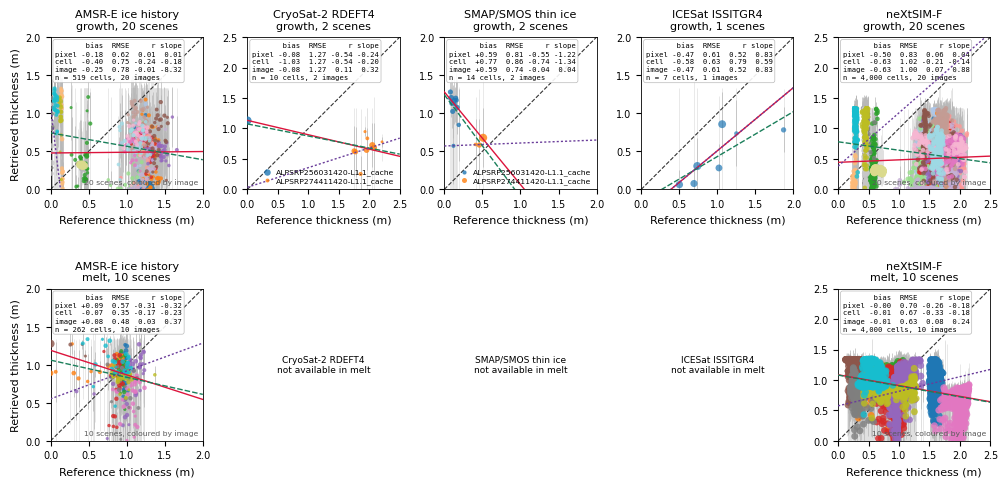

In [29]:
import matplotlib.pyplot as plt
summaries = pr.collect_summaries(targets)      # from disk
pr.seasonal_availability(summaries)                 # scenes and products per season
rows = pr.seasonal_comparison_table(summaries)      # rows carry a 'season' column
fig  = pr.plot_seasonal_comparison(summaries, figsize=(10,5), min_count=150); plt.savefig('figure10.1.png')
#pr.write_csv(rows, 'table5_seasonal.csv')




In [27]:
for targ in targets:
    pr.plot_region_cross_sections(targ)

no region profiles cached
no cached fields


In [ ]:
plt.subplots(

In [23]:
importlib.reload(pr)
targets = ['/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP167051410-L1.1_cache']
summaries = pr.collect_summaries(targets)      # from disk
#pr.availability_table(summaries)
#rows = pr.comparison_table(summaries)
#fig  = pr.plot_comparison(summaries)           # cell-mean panels
pr.replot_scenes(targets, im_figsize_base=(2.5,2.5), aspect=6, with_intensity=False)

[['/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP167051410-L1.1_cache/SIT_comparison.png',
  '/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP167051410-L1.1_cache/SIT_histograms.png',
  '/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP167051410-L1.1_cache/SIT_scatter.png',
  '/mnt/d/ALOS1-Landfast/BeaufortSouth/ALPSRP167051410-L1.1_cache/SIT_region_cores.png']]